# 15 — Temporal Graph Modeling: Node-GRU vs GCN-GRU vs GAT-GRU

**Goal:** test whether spatial graph structure becomes useful when it is combined with a multi-day temporal sequence.

Notebook 14 showed that the **static** graph representation did not improve the corrected-domain baseline:

- LR20 remained strongest;
- MLP20 was close to LR20;
- static GCN20 and GAT20 were lower;
- static GAT also tended to produce very high recall with weaker precision.

So the next hypothesis is:

> The missing information may not be static spatial structure alone, but the **evolution of spatial patterns over time**.

This notebook therefore compares temporal models under the same corrected 90-node domain and the same 150-km graph.

---

## Models

### 1. NodeGRU20
Each node is processed independently through time.

```text
node features over L days
        ↓
       GRU
        ↓
next-day hotspot probability
```

This is the **temporal-only control**.

### 2. GCN-GRU20
Each day first gets a fixed graph-convolution representation, then every node embedding is processed through GRU over time.

```text
daily graph → GCN → node embeddings
                         ↓
                       GRU
                         ↓
                  next-day hotspot
```

### 3. GAT-GRU20
Same idea, but spatial aggregation uses learned attention.

```text
daily graph → GAT → node embeddings
                         ↓
                       GRU
                         ↓
                  next-day hotspot
```

---

## Sequence lengths

Two sequence lengths are tested:

- **7 days**
- **14 days**

The purpose is sensitivity analysis, not aggressive validation tuning.

---

## Fairness controls

- same corrected 90 nodes;
- same 20 benchmark features;
- same 150-km graph;
- same train / validation dates;
- same internal early-stopping procedure;
- same three random seeds;
- September test stays unopened.

---

## Wind

Wind-aligned graph information is **not included yet**.

Notebook 13 suggested that wind may add signal for Emerging events, but it was not robust across all radii. Wind therefore remains a later ablation after the temporal graph architecture is evaluated.

## Environment

This notebook uses **PyTorch only** and does not require PyTorch Geometric.

It reuses the graph artifacts saved by Notebook 14 when available. If those artifacts are missing, it rebuilds the required tensors from the corrected CSV files.

In [8]:
# 1. Imports and reproducibility

from pathlib import Path
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import TensorDataset, DataLoader
except ImportError as exc:
    raise ImportError(
        "PyTorch is required. Install it in the active environment with "
        "`python -m pip install torch`, restart the kernel, then rerun."
    ) from exc

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
SEEDS = [42, 123, 2026]

pd.set_option("display.max_columns", 150)
pd.set_option("display.width", 220)


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_all_seeds(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch version :", torch.__version__)
print("Device          :", DEVICE)
print("Seeds           :", SEEDS)

PyTorch version : 2.14.0+cpu
Device          : cpu
Seeds           : [42, 123, 2026]


In [9]:
# 2. Resolve project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    corrected_ml = (
        candidate
        / "data"
        / "processed"
        / "spatial_corrected"
        / "karhut_ml_dataset_kalimantan_corrected.csv"
    )

    corrected_nodes = (
        candidate
        / "data"
        / "intermediate"
        / "spatial_corrected"
        / "kalimantan_graph_nodes_corrected.csv"
    )

    if corrected_ml.exists() and corrected_nodes.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not detect project root. Expected corrected outputs from Notebook 12B/12C."
    )

ML_INPUT = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spatial_corrected"
    / "karhut_ml_dataset_kalimantan_corrected.csv"
)

NODES_INPUT = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "spatial_corrected"
    / "kalimantan_graph_nodes_corrected.csv"
)

N14_ARTIFACTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "static_graph_baseline"
    / "artifacts"
)

GRAPH_NPZ = (
    N14_ARTIFACTS_DIR
    / "graph_inputs_r150km.npz"
)

EDGE_INPUT = (
    N14_ARTIFACTS_DIR
    / "graph_edges_r150km.csv"
)

N14_MAIN_COMPARISON = (
    PROJECT_ROOT
    / "model_results"
    / "static_graph_baseline"
    / "main_comparison.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "temporal_graph"
)

FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = RESULTS_DIR / "models"
ARTIFACTS_DIR = RESULTS_DIR / "artifacts"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT    :", PROJECT_ROOT)
print("Corrected ML    :", ML_INPUT)
print("N14 graph NPZ   :", GRAPH_NPZ)
print("Results         :", RESULTS_DIR)

PROJECT_ROOT    : c:\Users\Asus\Documents\skripsi-karhut
Corrected ML    : c:\Users\Asus\Documents\skripsi-karhut\data\processed\spatial_corrected\karhut_ml_dataset_kalimantan_corrected.csv
N14 graph NPZ   : c:\Users\Asus\Documents\skripsi-karhut\model_results\static_graph_baseline\artifacts\graph_inputs_r150km.npz
Results         : c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph


# PART A — Load / rebuild corrected graph tensors

## 3. Feature definitions

In [10]:
# 3. Strict 20-feature definition

fire_history_features = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

weather_features = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

features_20 = fire_history_features + weather_features
target_col = "target_fire_active_t1"

assert len(features_20) == 20

## 4. Load corrected table and fixed node order

In [11]:
# 4. Corrected dataframe and node order

ml = pd.read_csv(
    ML_INPUT,
    parse_dates=["date"],
)

nodes = pd.read_csv(
    NODES_INPUT,
)

ml = (
    ml
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

nodes = (
    nodes
    .sort_values("node_index")
    .reset_index(drop=True)
)

required_cols = {
    "cell_id",
    "date",
    target_col,
    "active_days_prev3_incl_t",
    "event_type_3d",
    *features_20,
}

missing = sorted(
    required_cols - set(ml.columns)
)

if missing:
    raise ValueError(
        f"Corrected ML file is missing columns: {missing}"
    )

assert ml.duplicated(["cell_id", "date"]).sum() == 0
assert nodes["cell_id"].duplicated().sum() == 0
assert set(ml["cell_id"].unique()) == set(nodes["cell_id"].unique())
assert ml[features_20].isna().sum().sum() == 0

node_order = (
    nodes[
        [
            "node_index",
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    ]
    .copy()
)

node_order["node_pos"] = np.arange(
    len(node_order)
)

N_NODES = len(node_order)

print("Corrected ML rows :", len(ml))
print("Nodes             :", N_NODES)
print(
    "Date range        :",
    ml["date"].min().date(),
    "→",
    ml["date"].max().date(),
)

Corrected ML rows : 11340
Nodes             : 90
Date range        : 2026-05-08 → 2026-09-10


## 5. Load Notebook 14 graph artifacts when available

The saved standardized tensor is preferred because it guarantees the same node order and scaling used in Notebook 14.

A fallback rebuild is included for portability.

In [12]:
# 5. Load / rebuild graph tensors

if GRAPH_NPZ.exists():

    graph_data = np.load(
        GRAPH_NPZ,
        allow_pickle=True,
    )

    X_scaled = graph_data["X_scaled"].astype(np.float32)
    y_np = graph_data["y"].astype(np.float32)
    eligible3_np = graph_data["eligible3"].astype(bool)

    all_dates = pd.to_datetime(
        graph_data["dates"].astype(str)
    )

    saved_node_ids = (
        graph_data["node_ids"]
        .astype(str)
    )

    A_norm = (
        graph_data["A_norm"]
        .astype(np.float32)
    )

    adj_mask = (
        graph_data["adj_mask"]
        .astype(bool)
    )

    expected_node_ids = (
        node_order["cell_id"]
        .astype(str)
        .to_numpy()
    )

    if not np.array_equal(
        saved_node_ids,
        expected_node_ids,
    ):
        raise AssertionError(
            "Notebook 14 artifact node order differs from current corrected nodes."
        )

    print("Loaded Notebook 14 graph artifact.")

Loaded Notebook 14 graph artifact.


## 6. Reconstruct 3-day event labels for subgroup recall

This is used only for positive-subgroup recall diagnostics.

In [13]:
# 6. Event type matrix

event3_list = []

for date in all_dates:

    day = (
        node_order[
            ["cell_id", "node_pos"]
        ]
        .merge(
            ml.loc[
                ml["date"].eq(date),
                [
                    "cell_id",
                    "event_type_3d",
                ],
            ],
            on="cell_id",
            how="left",
            validate="one_to_one",
        )
        .sort_values("node_pos")
    )

    event3_list.append(
        day["event_type_3d"]
        .astype(str)
        .to_numpy()
    )

event3_np = np.stack(
    event3_list
)

print(
    "Event-type matrix:",
    event3_np.shape,
)

Event-type matrix: (126, 90)


# PART B — Build temporal sequences

## 7. Sequence semantics

For a sequence ending on day `t`:

```text
X[t-L+1], ..., X[t]
```

the label is:

```text
y[t] = target hotspot at t+1
```

So the model never uses feature information from the target day `t+1`.

In [14]:
# 7. Sequence builder

SEQUENCE_LENGTHS = [
    7,
    14,
]


def build_sequences(
    X,
    y,
    eligible,
    events,
    dates,
    sequence_length,
):

    X_seq = []
    y_seq = []
    eligible_seq = []
    event_seq = []
    end_dates = []
    end_positions = []

    for end_idx in range(
        sequence_length - 1,
        len(dates),
    ):

        start_idx = (
            end_idx
            - sequence_length
            + 1
        )

        X_seq.append(
            X[
                start_idx:
                end_idx + 1
            ]
        )

        y_seq.append(
            y[end_idx]
        )

        eligible_seq.append(
            eligible[end_idx]
        )

        event_seq.append(
            events[end_idx]
        )

        end_dates.append(
            dates[end_idx]
        )

        end_positions.append(
            end_idx
        )

    return {
        "X": np.stack(X_seq).astype(np.float32),
        "y": np.stack(y_seq).astype(np.float32),
        "eligible3": np.stack(eligible_seq).astype(bool),
        "event3": np.stack(event_seq),
        "end_dates": pd.DatetimeIndex(end_dates),
        "end_positions": np.array(end_positions),
    }


sequence_data = {}

for length in SEQUENCE_LENGTHS:

    sequence_data[length] = (
        build_sequences(
            X_scaled,
            y_np,
            eligible3_np,
            event3_np,
            all_dates,
            sequence_length=length,
        )
    )

    current = sequence_data[length]

    print(
        f"L={length}:",
        "X",
        current["X"].shape,
        "| y",
        current["y"].shape,
        "| end dates",
        current["end_dates"][0].date(),
        "→",
        current["end_dates"][-1].date(),
    )

L=7: X (120, 7, 90, 20) | y (120, 90) | end dates 2026-05-14 → 2026-09-10
L=14: X (113, 14, 90, 20) | y (113, 90) | end dates 2026-05-21 → 2026-09-10


## 8. Split sequences by sequence end-date

The end-date `t` determines the split because the prediction target belongs to `t+1`.

August validation remains untouched during epoch selection.

In [15]:
# 8. Sequence split helper

INTERNAL_VAL_DAYS = 14


def sequence_split_masks(
    end_dates,
):

    train_mask = (
        end_dates
        < pd.Timestamp(
            "2026-08-01"
        )
    )

    val_mask = (
        (
            end_dates
            >= pd.Timestamp(
                "2026-08-01"
            )
        )
        &
        (
            end_dates
            < pd.Timestamp(
                "2026-09-01"
            )
        )
    )

    test_mask = (
        end_dates
        >= pd.Timestamp(
            "2026-09-01"
        )
    )

    train_dates = end_dates[
        train_mask
    ]

    internal_val_dates = (
        train_dates[
            -INTERNAL_VAL_DAYS:
        ]
    )

    fit_dates = (
        train_dates[
            :-INTERNAL_VAL_DAYS
        ]
    )

    fit_mask = end_dates.isin(
        fit_dates
    )

    internal_mask = end_dates.isin(
        internal_val_dates
    )

    return {
        "fit": np.asarray(fit_mask),
        "internal": np.asarray(internal_mask),
        "train": np.asarray(train_mask),
        "val": np.asarray(val_mask),
        "test": np.asarray(test_mask),
    }


split_masks = {}

split_rows = []

for length in SEQUENCE_LENGTHS:

    end_dates = (
        sequence_data[length][
            "end_dates"
        ]
    )

    masks = (
        sequence_split_masks(
            end_dates
        )
    )

    split_masks[length] = masks

    split_rows.append({
        "Sequence Length": length,
        "Fit Sequences": int(
            masks["fit"].sum()
        ),
        "Internal Sequences": int(
            masks["internal"].sum()
        ),
        "Full Train Sequences": int(
            masks["train"].sum()
        ),
        "August Validation Sequences": int(
            masks["val"].sum()
        ),
        "September Test Sequences": int(
            masks["test"].sum()
        ),
    })

split_summary = pd.DataFrame(
    split_rows
)

display(split_summary)

,Sequence Length,Fit Sequences,Internal Sequences,Full Train Sequences,August Validation Sequences,September Test Sequences
0,7,65,14,79,31,10
1,14,58,14,72,31,10


# PART C — Baseline LR20 reference

## 9. Refit corrected LR20 for reference

This is the same static day-`t` baseline used in Notebook 12C/14.

In [16]:
# 9. Corrected LR20 reference

train_df = ml[
    ml["date"]
    < "2026-08-01"
].copy()

val_df = ml[
    (
        ml["date"]
        >= "2026-08-01"
    )
    &
    (
        ml["date"]
        < "2026-09-01"
    )
].copy()

lr20 = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE,
        ),
    ),
])

lr20.fit(
    train_df[features_20],
    train_df[target_col].astype(int),
)

lr_val_prob = (
    lr20
    .predict_proba(
        val_df[features_20]
    )[:, 1]
)

lr_val_y = (
    val_df[target_col]
    .astype(int)
    .to_numpy()
)


def metric_dict(
    y_true,
    probability,
    threshold=0.50,
):

    y_true = np.asarray(
        y_true
    ).astype(int)

    probability = np.asarray(
        probability
    )

    prediction = (
        probability
        >= threshold
    ).astype(int)

    return {
        "PR-AUC": average_precision_score(
            y_true,
            probability,
        ),
        "ROC-AUC": roc_auc_score(
            y_true,
            probability,
        ),
        "Precision": precision_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "F1": f1_score(
            y_true,
            prediction,
            zero_division=0,
        ),
        "Accuracy": accuracy_score(
            y_true,
            prediction,
        ),
        "Threshold": threshold,
    }


lr_metrics = metric_dict(
    lr_val_y,
    lr_val_prob,
)

display(
    pd.DataFrame([
        {
            "Model": "LR20",
            **lr_metrics,
        }
    ])
)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR20,0.955283,0.884426,0.86602,0.939742,0.901376,0.845878,0.5


# PART D — Temporal model definitions

## 10. Shared graph layers

In [17]:
# 10. Dense GCN and GAT layers

class DenseGCNLayer(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim,
    ):
        super().__init__()

        self.linear = nn.Linear(
            in_dim,
            out_dim,
        )

    def forward(
        self,
        x,
        a_norm,
    ):

        h = self.linear(
            x
        )

        return torch.einsum(
            "ij,bjf->bif",
            a_norm,
            h,
        )


class DenseGATLayer(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim,
        heads=1,
        concat=True,
        dropout=0.15,
        negative_slope=0.2,
    ):
        super().__init__()

        self.in_dim = in_dim
        self.out_dim = out_dim
        self.heads = heads
        self.concat = concat
        self.dropout = dropout
        self.negative_slope = (
            negative_slope
        )

        self.linear = nn.Linear(
            in_dim,
            heads * out_dim,
            bias=False,
        )

        self.attn_target = (
            nn.Parameter(
                torch.empty(
                    heads,
                    out_dim,
                )
            )
        )

        self.attn_source = (
            nn.Parameter(
                torch.empty(
                    heads,
                    out_dim,
                )
            )
        )

        if concat:
            bias_dim = (
                heads
                * out_dim
            )
        else:
            bias_dim = (
                out_dim
            )

        self.bias = nn.Parameter(
            torch.zeros(
                bias_dim
            )
        )

        self.reset_parameters()

    def reset_parameters(self):

        nn.init.xavier_uniform_(
            self.linear.weight
        )

        nn.init.xavier_uniform_(
            self.attn_target
        )

        nn.init.xavier_uniform_(
            self.attn_source
        )

        nn.init.zeros_(
            self.bias
        )

    def forward(
        self,
        x,
        adj_mask,
    ):
        # x: [B, N, F]

        batch_size, n_nodes, _ = (
            x.shape
        )

        h = (
            self.linear(x)
            .view(
                batch_size,
                n_nodes,
                self.heads,
                self.out_dim,
            )
        )

        target_score = (
            h
            * self.attn_target[
                None,
                None,
                :,
                :,
            ]
        ).sum(
            dim=-1
        )

        source_score = (
            h
            * self.attn_source[
                None,
                None,
                :,
                :,
            ]
        ).sum(
            dim=-1
        )

        e = (
            target_score[
                :,
                :,
                None,
                :,
            ]
            +
            source_score[
                :,
                None,
                :,
                :,
            ]
        )

        e = F.leaky_relu(
            e,
            negative_slope=self.negative_slope,
        )

        mask = (
            adj_mask[
                None,
                :,
                :,
                None,
            ]
        )

        e = e.masked_fill(
            ~mask,
            -1e9,
        )

        alpha = torch.softmax(
            e,
            dim=2,
        )

        alpha = F.dropout(
            alpha,
            p=self.dropout,
            training=self.training,
        )

        out = torch.einsum(
            "btsh,bshd->bthd",
            alpha,
            h,
        )

        if self.concat:

            out = out.reshape(
                batch_size,
                n_nodes,
                self.heads
                * self.out_dim,
            )

        else:

            out = out.mean(
                dim=2
            )

        return (
            out
            + self.bias
        )

## 11. Temporal-only NodeGRU20

In [18]:
# 11. Node-wise GRU

class NodeGRU(nn.Module):

    def __init__(
        self,
        in_dim,
        hidden_dim=32,
        dropout=0.15,
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=in_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )

        self.dropout = dropout

        self.out = nn.Linear(
            hidden_dim,
            1,
        )

    def forward(
        self,
        x,
        a_norm=None,
        adj_mask=None,
    ):
        # x: [B, L, N, F]

        batch_size, seq_len, n_nodes, n_features = (
            x.shape
        )

        node_sequences = (
            x
            .permute(
                0,
                2,
                1,
                3,
            )
            .reshape(
                batch_size
                * n_nodes,
                seq_len,
                n_features,
            )
        )

        _, h = self.gru(
            node_sequences
        )

        h = h[-1]

        h = F.dropout(
            h,
            p=self.dropout,
            training=self.training,
        )

        logits = (
            self.out(h)
            .reshape(
                batch_size,
                n_nodes,
            )
        )

        return logits

## 12. GCN-GRU20

In [19]:
# 12. GCN per day + GRU per node

class GCNGRU(nn.Module):

    def __init__(
        self,
        in_dim,
        spatial_dim=24,
        temporal_dim=32,
        dropout=0.15,
    ):
        super().__init__()

        self.gcn = DenseGCNLayer(
            in_dim,
            spatial_dim,
        )

        self.gru = nn.GRU(
            input_size=spatial_dim,
            hidden_size=temporal_dim,
            batch_first=True,
        )

        self.dropout = dropout

        self.out = nn.Linear(
            temporal_dim,
            1,
        )

    def forward(
        self,
        x,
        a_norm,
        adj_mask=None,
    ):
        # x: [B, L, N, F]

        batch_size, seq_len, n_nodes, n_features = (
            x.shape
        )

        daily = x.reshape(
            batch_size
            * seq_len,
            n_nodes,
            n_features,
        )

        spatial = self.gcn(
            daily,
            a_norm,
        )

        spatial = F.relu(
            spatial
        )

        spatial = F.dropout(
            spatial,
            p=self.dropout,
            training=self.training,
        )

        spatial = spatial.reshape(
            batch_size,
            seq_len,
            n_nodes,
            -1,
        )

        node_sequences = (
            spatial
            .permute(
                0,
                2,
                1,
                3,
            )
            .reshape(
                batch_size
                * n_nodes,
                seq_len,
                spatial.shape[-1],
            )
        )

        _, h = self.gru(
            node_sequences
        )

        h = F.dropout(
            h[-1],
            p=self.dropout,
            training=self.training,
        )

        logits = (
            self.out(h)
            .reshape(
                batch_size,
                n_nodes,
            )
        )

        return logits

## 13. GAT-GRU20

In [20]:
# 13. GAT per day + GRU per node

class GATGRU(nn.Module):

    def __init__(
        self,
        in_dim,
        hidden_per_head=6,
        heads=4,
        temporal_dim=32,
        dropout=0.15,
    ):
        super().__init__()

        self.gat = DenseGATLayer(
            in_dim=in_dim,
            out_dim=hidden_per_head,
            heads=heads,
            concat=True,
            dropout=dropout,
        )

        spatial_dim = (
            hidden_per_head
            * heads
        )

        self.gru = nn.GRU(
            input_size=spatial_dim,
            hidden_size=temporal_dim,
            batch_first=True,
        )

        self.dropout = dropout

        self.out = nn.Linear(
            temporal_dim,
            1,
        )

    def forward(
        self,
        x,
        a_norm=None,
        adj_mask=None,
    ):
        # x: [B, L, N, F]

        batch_size, seq_len, n_nodes, n_features = (
            x.shape
        )

        daily = x.reshape(
            batch_size
            * seq_len,
            n_nodes,
            n_features,
        )

        spatial = self.gat(
            daily,
            adj_mask,
        )

        spatial = F.elu(
            spatial
        )

        spatial = F.dropout(
            spatial,
            p=self.dropout,
            training=self.training,
        )

        spatial = spatial.reshape(
            batch_size,
            seq_len,
            n_nodes,
            -1,
        )

        node_sequences = (
            spatial
            .permute(
                0,
                2,
                1,
                3,
            )
            .reshape(
                batch_size
                * n_nodes,
                seq_len,
                spatial.shape[-1],
            )
        )

        _, h = self.gru(
            node_sequences
        )

        h = F.dropout(
            h[-1],
            p=self.dropout,
            training=self.training,
        )

        logits = (
            self.out(h)
            .reshape(
                batch_size,
                n_nodes,
            )
        )

        return logits

## 14. Fixed architecture / optimizer configuration

Hyperparameters are intentionally modest because the dataset has only about a few dozen independent daily training snapshots after sequence construction.

In [21]:
# 14. Model factories

MODEL_FACTORIES = {
    "NodeGRU20": lambda: NodeGRU(
        in_dim=len(features_20),
        hidden_dim=32,
        dropout=0.15,
    ),

    "GCN-GRU20": lambda: GCNGRU(
        in_dim=len(features_20),
        spatial_dim=24,
        temporal_dim=32,
        dropout=0.15,
    ),

    "GAT-GRU20": lambda: GATGRU(
        in_dim=len(features_20),
        hidden_per_head=6,
        heads=4,
        temporal_dim=32,
        dropout=0.15,
    ),
}

OPTIMIZER_CONFIG = {
    "NodeGRU20": {
        "lr": 0.003,
        "weight_decay": 1e-4,
    },

    "GCN-GRU20": {
        "lr": 0.003,
        "weight_decay": 1e-4,
    },

    "GAT-GRU20": {
        "lr": 0.002,
        "weight_decay": 1e-4,
    },
}

MAX_EPOCHS = 220
PATIENCE = 30
MIN_DELTA = 1e-4
BATCH_SIZE = 8

parameter_rows = []

for model_name, factory in MODEL_FACTORIES.items():

    model = factory()

    parameter_rows.append({
        "Model": model_name,
        "Trainable Parameters": sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        ),
    })

parameter_table = pd.DataFrame(
    parameter_rows
)

display(
    parameter_table
)

print("Max epochs :", MAX_EPOCHS)
print("Patience   :", PATIENCE)
print("Batch size :", BATCH_SIZE)

,Model,Trainable Parameters
0,NodeGRU20,5217
1,GCN-GRU20,6105
2,GAT-GRU20,6153


Max epochs : 220
Patience   : 30
Batch size : 8


# PART E — Training helpers

## 15. Tensor / loader helpers

In [22]:
# 15. Tensor helpers

A_norm_tensor = torch.tensor(
    A_norm,
    dtype=torch.float32,
    device=DEVICE,
)

adj_mask_tensor = torch.tensor(
    adj_mask,
    dtype=torch.bool,
    device=DEVICE,
)


def numpy_to_dataset(
    X,
    y,
):

    return TensorDataset(
        torch.tensor(
            X,
            dtype=torch.float32,
        ),
        torch.tensor(
            y,
            dtype=torch.float32,
        ),
    )


def make_loader(
    X,
    y,
    batch_size=BATCH_SIZE,
    shuffle=False,
):

    dataset = numpy_to_dataset(
        X,
        y,
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=False,
    )


def compute_pos_weight(
    y_array,
):

    positives = float(
        np.asarray(
            y_array
        ).sum()
    )

    total = float(
        np.asarray(
            y_array
        ).size
    )

    negatives = (
        total
        - positives
    )

    if positives <= 0:
        return 1.0

    return (
        negatives
        / positives
    )

## 16. Validation prediction helper

In [23]:
# 16. Prediction helper

def predict_loader(
    model,
    loader,
):

    model.eval()

    probabilities = []
    labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = (
                X_batch
                .to(DEVICE)
            )

            logits = model(
                X_batch,
                A_norm_tensor,
                adj_mask_tensor,
            )

            probability = (
                torch.sigmoid(
                    logits
                )
                .detach()
                .cpu()
                .numpy()
            )

            probabilities.append(
                probability
            )

            labels.append(
                y_batch.numpy()
            )

    return (
        np.concatenate(
            probabilities,
            axis=0,
        ),
        np.concatenate(
            labels,
            axis=0,
        ),
    )

## 17. Internal early stopping

Best epoch is selected only on the final 14 days **inside the May–July training period**.

In [24]:
# 17. Internal tuning function

def tune_best_epoch(
    model_name,
    sequence_length,
    seed,
):

    set_all_seeds(
        seed
    )

    data = (
        sequence_data[
            sequence_length
        ]
    )

    masks = (
        split_masks[
            sequence_length
        ]
    )

    X_fit = data["X"][
        masks["fit"]
    ]

    y_fit = data["y"][
        masks["fit"]
    ]

    X_internal = data["X"][
        masks["internal"]
    ]

    y_internal = data["y"][
        masks["internal"]
    ]

    fit_loader = make_loader(
        X_fit,
        y_fit,
        shuffle=True,
    )

    internal_loader = make_loader(
        X_internal,
        y_internal,
        shuffle=False,
    )

    model = (
        MODEL_FACTORIES[
            model_name
        ]()
        .to(DEVICE)
    )

    config = (
        OPTIMIZER_CONFIG[
            model_name
        ]
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    pos_weight = compute_pos_weight(
        y_fit
    )

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            pos_weight,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    best_pr_auc = -np.inf
    best_epoch = 1
    stale = 0
    history = []

    start = time.perf_counter()

    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):

        model.train()

        epoch_losses = []

        for X_batch, y_batch in fit_loader:

            X_batch = (
                X_batch
                .to(DEVICE)
            )

            y_batch = (
                y_batch
                .to(DEVICE)
            )

            optimizer.zero_grad()

            logits = model(
                X_batch,
                A_norm_tensor,
                adj_mask_tensor,
            )

            loss = loss_fn(
                logits,
                y_batch,
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0,
            )

            optimizer.step()

            epoch_losses.append(
                float(
                    loss.item()
                )
            )

        internal_prob, internal_y = predict_loader(
            model,
            internal_loader,
        )

        internal_pr_auc = average_precision_score(
            internal_y.reshape(-1),
            internal_prob.reshape(-1),
        )

        history.append({
            "Model": model_name,
            "Sequence Length": sequence_length,
            "Seed": seed,
            "Epoch": epoch,
            "Fit Loss": float(
                np.mean(
                    epoch_losses
                )
            ),
            "Internal PR-AUC": float(
                internal_pr_auc
            ),
        })

        if (
            internal_pr_auc
            > best_pr_auc
            + MIN_DELTA
        ):

            best_pr_auc = (
                internal_pr_auc
            )

            best_epoch = epoch
            stale = 0

        else:

            stale += 1

        if stale >= PATIENCE:
            break

    elapsed = (
        time.perf_counter()
        - start
    )

    return {
        "Model": model_name,
        "Sequence Length": sequence_length,
        "Seed": seed,
        "Best Epoch": int(
            best_epoch
        ),
        "Best Internal PR-AUC": float(
            best_pr_auc
        ),
        "Tuning Seconds": float(
            elapsed
        ),
        "History": pd.DataFrame(
            history
        ),
    }

## 18. Final retraining on full May–July window

In [25]:
# 18. Final training function

def train_full_model(
    model_name,
    sequence_length,
    seed,
    epochs,
):

    set_all_seeds(
        seed
    )

    data = (
        sequence_data[
            sequence_length
        ]
    )

    masks = (
        split_masks[
            sequence_length
        ]
    )

    X_train = data["X"][
        masks["train"]
    ]

    y_train = data["y"][
        masks["train"]
    ]

    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True,
    )

    model = (
        MODEL_FACTORIES[
            model_name
        ]()
        .to(DEVICE)
    )

    config = (
        OPTIMIZER_CONFIG[
            model_name
        ]
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    pos_weight = compute_pos_weight(
        y_train
    )

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            pos_weight,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    start = time.perf_counter()

    final_loss = np.nan

    for epoch in range(
        1,
        epochs + 1,
    ):

        model.train()

        epoch_losses = []

        for X_batch, y_batch in train_loader:

            X_batch = (
                X_batch
                .to(DEVICE)
            )

            y_batch = (
                y_batch
                .to(DEVICE)
            )

            optimizer.zero_grad()

            logits = model(
                X_batch,
                A_norm_tensor,
                adj_mask_tensor,
            )

            loss = loss_fn(
                logits,
                y_batch,
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0,
            )

            optimizer.step()

            epoch_losses.append(
                float(
                    loss.item()
                )
            )

        final_loss = float(
            np.mean(
                epoch_losses
            )
        )

    elapsed = (
        time.perf_counter()
        - start
    )

    return (
        model,
        elapsed,
        final_loss,
    )

# PART F — Run temporal experiments

## 19. Internal tuning: 3 models × 2 sequence lengths × 3 seeds

This is the heaviest cell in Notebook 15.

In [26]:
# 19. Internal tuning runs

tuning_rows = []
history_frames = []

for sequence_length in SEQUENCE_LENGTHS:

    for model_name in MODEL_FACTORIES:

        for seed in SEEDS:

            print(
                f"Tuning {model_name} | "
                f"L={sequence_length} | "
                f"seed={seed}"
            )

            result = tune_best_epoch(
                model_name=model_name,
                sequence_length=sequence_length,
                seed=seed,
            )

            tuning_rows.append({
                "Model": result["Model"],
                "Sequence Length": result["Sequence Length"],
                "Seed": result["Seed"],
                "Best Epoch": result["Best Epoch"],
                "Best Internal PR-AUC": result["Best Internal PR-AUC"],
                "Tuning Seconds": result["Tuning Seconds"],
            })

            history_frames.append(
                result["History"]
            )


tuning_summary = pd.DataFrame(
    tuning_rows
)

tuning_history = pd.concat(
    history_frames,
    ignore_index=True,
)

display(
    tuning_summary
)

Tuning NodeGRU20 | L=7 | seed=42
Tuning NodeGRU20 | L=7 | seed=123
Tuning NodeGRU20 | L=7 | seed=2026
Tuning GCN-GRU20 | L=7 | seed=42
Tuning GCN-GRU20 | L=7 | seed=123
Tuning GCN-GRU20 | L=7 | seed=2026
Tuning GAT-GRU20 | L=7 | seed=42
Tuning GAT-GRU20 | L=7 | seed=123
Tuning GAT-GRU20 | L=7 | seed=2026
Tuning NodeGRU20 | L=14 | seed=42
Tuning NodeGRU20 | L=14 | seed=123
Tuning NodeGRU20 | L=14 | seed=2026
Tuning GCN-GRU20 | L=14 | seed=42
Tuning GCN-GRU20 | L=14 | seed=123
Tuning GCN-GRU20 | L=14 | seed=2026
Tuning GAT-GRU20 | L=14 | seed=42
Tuning GAT-GRU20 | L=14 | seed=123
Tuning GAT-GRU20 | L=14 | seed=2026


,Model,Sequence Length,Seed,Best Epoch,Best Internal PR-AUC,Tuning Seconds
0,NodeGRU20,7,42,7,0.817685,3.882388
1,NodeGRU20,7,123,3,0.817190,3.289454
2,NodeGRU20,7,2026,2,0.821569,3.026217
3,GCN-GRU20,7,42,2,0.785481,5.411423
4,GCN-GRU20,7,123,3,0.754606,4.911429
5,GCN-GRU20,7,2026,5,0.789449,5.091039
6,GAT-GRU20,7,42,13,0.781723,28.323464
7,GAT-GRU20,7,123,4,0.770041,22.702761
8,GAT-GRU20,7,2026,5,0.791167,23.557675
9,NodeGRU20,14,42,9,0.829349,6.309582


## 20. Internal tuning summary by model / sequence length

In [27]:
# 20. Aggregate internal tuning

tuning_aggregate = (
    tuning_summary
    .groupby(
        [
            "Model",
            "Sequence Length",
        ],
        as_index=False,
    )
    .agg(
        Mean_Best_Epoch=(
            "Best Epoch",
            "mean",
        ),
        Std_Best_Epoch=(
            "Best Epoch",
            "std",
        ),
        Mean_Internal_PR_AUC=(
            "Best Internal PR-AUC",
            "mean",
        ),
        Std_Internal_PR_AUC=(
            "Best Internal PR-AUC",
            "std",
        ),
        Mean_Tuning_Seconds=(
            "Tuning Seconds",
            "mean",
        ),
    )
)

display(
    tuning_aggregate
)

,Model,Sequence Length,Mean_Best_Epoch,Std_Best_Epoch,Mean_Internal_PR_AUC,Std_Internal_PR_AUC,Mean_Tuning_Seconds
0,GAT-GRU20,7,7.333333,4.932883,0.780977,0.010583,24.861300
1,GAT-GRU20,14,6.666667,2.886751,0.781708,0.015696,41.899445
2,GCN-GRU20,7,3.333333,1.527525,0.776512,0.019075,5.137964
3,GCN-GRU20,14,3.333333,1.527525,0.776391,0.022213,7.614824
4,NodeGRU20,7,4.000000,2.645751,0.818815,0.002398,3.399353
5,NodeGRU20,14,7.333333,3.785939,0.826105,0.002899,6.033808


## 21. Internal tuning curves

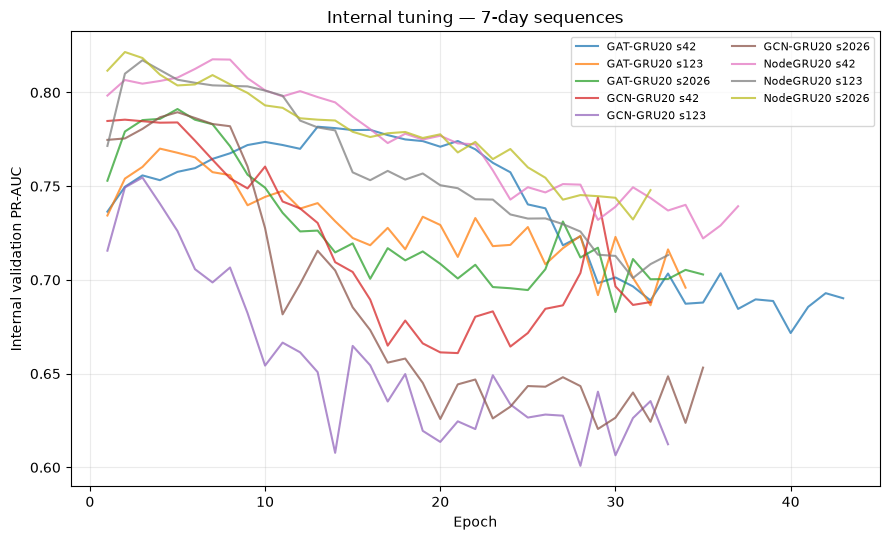

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\figures\01_internal_tuning_L7.png


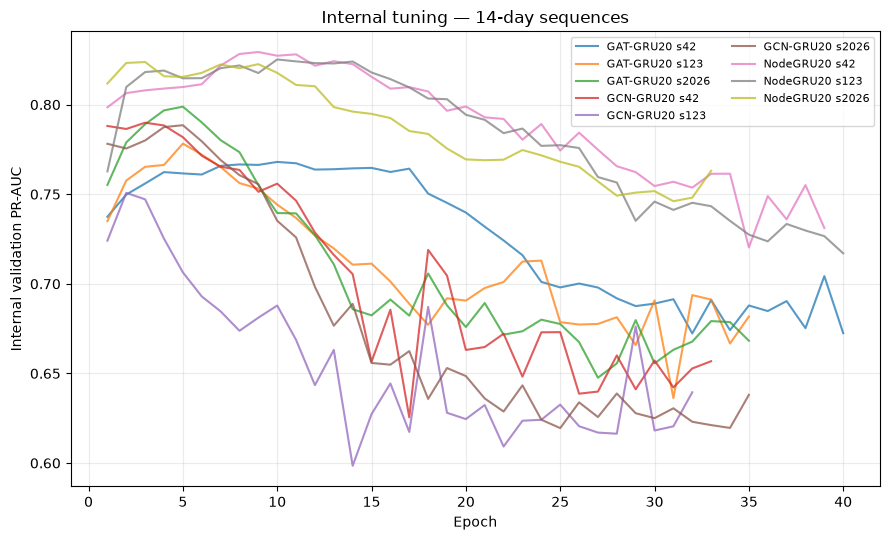

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\figures\01_internal_tuning_L14.png


In [28]:
# 21. Internal tuning curves

for sequence_length in SEQUENCE_LENGTHS:

    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    subset = tuning_history[
        tuning_history[
            "Sequence Length"
        ].eq(
            sequence_length
        )
    ]

    for (
        model_name,
        seed,
    ), group in subset.groupby(
        [
            "Model",
            "Seed",
        ]
    ):

        ax.plot(
            group["Epoch"],
            group[
                "Internal PR-AUC"
            ],
            alpha=0.75,
            label=(
                f"{model_name} "
                f"s{seed}"
            ),
        )

    ax.set_xlabel(
        "Epoch"
    )

    ax.set_ylabel(
        "Internal validation PR-AUC"
    )

    ax.set_title(
        f"Internal tuning — "
        f"{sequence_length}-day sequences"
    )

    ax.legend(
        ncol=2,
        fontsize=8,
    )

    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()

    path = (
        FIGURES_DIR
        / f"01_internal_tuning_L{sequence_length}.png"
    )

    plt.savefig(
        path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Saved:",
        path,
    )

## 22. Retrain full May–July and evaluate August

In [29]:
# 22. Final temporal runs

final_rows = []
final_models = {}
final_val_probs = {}

for row in tuning_summary.itertuples(
    index=False
):

    model_name = row.Model
    sequence_length = int(
        getattr(
            row,
            "_1",
            row[1],
        )
    )
    seed = int(
        row.Seed
    )

    best_epoch = int(
        tuning_summary.loc[
            (
                tuning_summary[
                    "Model"
                ].eq(
                    model_name
                )
            )
            &
            (
                tuning_summary[
                    "Sequence Length"
                ].eq(
                    sequence_length
                )
            )
            &
            (
                tuning_summary[
                    "Seed"
                ].eq(
                    seed
                )
            ),
            "Best Epoch",
        ].iloc[0]
    )

    print(
        f"Final {model_name} | "
        f"L={sequence_length} | "
        f"seed={seed} | "
        f"epochs={best_epoch}"
    )

    model, training_seconds, final_loss = (
        train_full_model(
            model_name=model_name,
            sequence_length=sequence_length,
            seed=seed,
            epochs=best_epoch,
        )
    )

    data = (
        sequence_data[
            sequence_length
        ]
    )

    masks = (
        split_masks[
            sequence_length
        ]
    )

    val_loader = make_loader(
        data["X"][
            masks["val"]
        ],
        data["y"][
            masks["val"]
        ],
        shuffle=False,
    )

    probability, y_true = (
        predict_loader(
            model,
            val_loader,
        )
    )

    metrics = metric_dict(
        y_true.reshape(-1),
        probability.reshape(-1),
        threshold=0.50,
    )

    final_rows.append({
        "Model": model_name,
        "Sequence Length": sequence_length,
        "Seed": seed,
        "Best Epoch": best_epoch,
        **metrics,
        "Training Seconds": training_seconds,
        "Final Train Loss": final_loss,
    })

    key = (
        model_name,
        sequence_length,
        seed,
    )

    final_models[key] = model
    final_val_probs[key] = (
        probability
    )


temporal_results = pd.DataFrame(
    final_rows
)

display(
    temporal_results
)

Final NodeGRU20 | L=7 | seed=42 | epochs=7
Final NodeGRU20 | L=7 | seed=123 | epochs=3
Final NodeGRU20 | L=7 | seed=2026 | epochs=2
Final GCN-GRU20 | L=7 | seed=42 | epochs=2
Final GCN-GRU20 | L=7 | seed=123 | epochs=3
Final GCN-GRU20 | L=7 | seed=2026 | epochs=5
Final GAT-GRU20 | L=7 | seed=42 | epochs=13
Final GAT-GRU20 | L=7 | seed=123 | epochs=4
Final GAT-GRU20 | L=7 | seed=2026 | epochs=5
Final NodeGRU20 | L=14 | seed=42 | epochs=9
Final NodeGRU20 | L=14 | seed=123 | epochs=10
Final NodeGRU20 | L=14 | seed=2026 | epochs=3
Final GCN-GRU20 | L=14 | seed=42 | epochs=3
Final GCN-GRU20 | L=14 | seed=123 | epochs=2
Final GCN-GRU20 | L=14 | seed=2026 | epochs=5
Final GAT-GRU20 | L=14 | seed=42 | epochs=10
Final GAT-GRU20 | L=14 | seed=123 | epochs=5
Final GAT-GRU20 | L=14 | seed=2026 | epochs=5


,Model,Sequence Length,Seed,Best Epoch,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold,Training Seconds,Final Train Loss
0,NodeGRU20,7,42,7,0.934425,0.868753,0.843580,0.964610,0.900045,0.839427,0.5,0.787629,0.772091
1,NodeGRU20,7,123,3,0.945008,0.880313,0.854991,0.950263,0.900113,0.841935,0.5,0.342205,0.849994
2,NodeGRU20,7,2026,2,0.944012,0.881676,0.848847,0.950741,0.896910,0.836201,0.5,0.209852,0.861578
3,GCN-GRU20,7,42,2,0.927067,0.838278,0.801823,0.967480,0.876896,0.796416,0.5,0.349116,0.883140
4,GCN-GRU20,7,123,3,0.920362,0.825639,0.820322,0.949785,0.880319,0.806452,0.5,0.496763,0.866306
5,GCN-GRU20,7,2026,5,0.923563,0.827582,0.789678,0.973219,0.871894,0.785663,0.5,0.821650,0.831421
6,GAT-GRU20,7,42,13,0.920736,0.813418,0.768515,0.987566,0.864378,0.767742,0.5,9.536451,0.792557
7,GAT-GRU20,7,123,4,0.877047,0.774169,0.792607,0.974175,0.874061,0.789606,0.5,2.988968,0.849286
8,GAT-GRU20,7,2026,5,0.859484,0.734491,0.783608,0.978479,0.870268,0.781362,0.5,3.696618,0.831370
9,NodeGRU20,14,42,9,0.949337,0.886026,0.829248,0.970827,0.894470,0.828315,0.5,1.604415,0.758781


## 23. Aggregate August results across seeds

In [30]:
# 23. Aggregate temporal validation results

aggregate_rows = []

metric_cols = [
    "PR-AUC",
    "ROC-AUC",
    "Precision",
    "Recall",
    "F1",
    "Accuracy",
    "Best Epoch",
    "Training Seconds",
]

for (
    model_name,
    sequence_length,
), group in temporal_results.groupby(
    [
        "Model",
        "Sequence Length",
    ]
):

    result = {
        "Model": model_name,
        "Sequence Length": sequence_length,
        "Seeds": len(group),
    }

    for metric in metric_cols:

        result[
            f"{metric} Mean"
        ] = group[
            metric
        ].mean()

        result[
            f"{metric} Std"
        ] = group[
            metric
        ].std(
            ddof=1
        )

    aggregate_rows.append(
        result
    )


temporal_aggregate = pd.DataFrame(
    aggregate_rows
)

display(
    temporal_aggregate
)

,Model,Sequence Length,Seeds,PR-AUC Mean,PR-AUC Std,ROC-AUC Mean,ROC-AUC Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Accuracy Mean,Accuracy Std,Best Epoch Mean,Best Epoch Std,Training Seconds Mean,Training Seconds Std
0,GAT-GRU20,7,3,0.885756,0.031541,0.774026,0.039464,0.781577,0.012174,0.980073,0.006836,0.869569,0.004879,0.779570,0.011042,7.333333,4.932883,5.407346,3.593372
1,GAT-GRU20,14,3,0.897018,0.032482,0.788335,0.038643,0.784690,0.006722,0.976247,0.005706,0.870020,0.001906,0.781362,0.004966,6.666667,2.886751,8.772197,3.828395
2,GCN-GRU20,7,3,0.923664,0.003353,0.830500,0.006805,0.803941,0.015432,0.963494,0.012215,0.876370,0.004237,0.796177,0.010396,3.333333,1.527525,0.555843,0.241743
3,GCN-GRU20,14,3,0.925733,0.007622,0.833101,0.011579,0.810992,0.029606,0.955045,0.034297,0.876382,0.002417,0.797969,0.011387,3.333333,1.527525,0.880637,0.412123
4,NodeGRU20,7,3,0.941148,0.005844,0.876914,0.007100,0.849140,0.005711,0.955205,0.008149,0.899022,0.001830,0.839188,0.002875,4.000000,2.645751,0.446562,0.302695
5,NodeGRU20,14,3,0.948056,0.001349,0.882070,0.003478,0.840336,0.021349,0.962538,0.013946,0.897060,0.005944,0.834289,0.012910,7.333333,3.785939,1.318478,0.671167


# PART G — Interpret graph gain fairly

## 24. Compare temporal graph models against temporal-only NodeGRU

The most important graph-specific comparisons are:

```text
GCN-GRU − NodeGRU
GAT-GRU − NodeGRU
```

for the **same sequence length**.

This separates temporal modeling benefit from graph benefit.

In [31]:
# 24. Temporal mechanism deltas

mechanism_rows = []

for sequence_length in SEQUENCE_LENGTHS:

    sub = (
        temporal_aggregate[
            temporal_aggregate[
                "Sequence Length"
            ].eq(
                sequence_length
            )
        ]
        .set_index(
            "Model"
        )
    )

    node_ap = sub.loc[
        "NodeGRU20",
        "PR-AUC Mean",
    ]

    gcn_ap = sub.loc[
        "GCN-GRU20",
        "PR-AUC Mean",
    ]

    gat_ap = sub.loc[
        "GAT-GRU20",
        "PR-AUC Mean",
    ]

    mechanism_rows.extend([
        {
            "Sequence Length": sequence_length,
            "Comparison": "NodeGRU20 − LR20",
            "Interpretation": "temporal sequence beyond static LR",
            "Δ PR-AUC": (
                node_ap
                - lr_metrics[
                    "PR-AUC"
                ]
            ),
        },
        {
            "Sequence Length": sequence_length,
            "Comparison": "GCN-GRU20 − NodeGRU20",
            "Interpretation": "fixed graph gain beyond temporal-only GRU",
            "Δ PR-AUC": (
                gcn_ap
                - node_ap
            ),
        },
        {
            "Sequence Length": sequence_length,
            "Comparison": "GAT-GRU20 − NodeGRU20",
            "Interpretation": "attention graph gain beyond temporal-only GRU",
            "Δ PR-AUC": (
                gat_ap
                - node_ap
            ),
        },
        {
            "Sequence Length": sequence_length,
            "Comparison": "GAT-GRU20 − GCN-GRU20",
            "Interpretation": "attention vs fixed graph aggregation",
            "Δ PR-AUC": (
                gat_ap
                - gcn_ap
            ),
        },
    ])


mechanism_deltas = pd.DataFrame(
    mechanism_rows
)

display(
    mechanism_deltas
)

,Sequence Length,Comparison,Interpretation,Δ PR-AUC
0,7,NodeGRU20 − LR20,temporal sequence beyond static LR,-0.014134
1,7,GCN-GRU20 − NodeGRU20,fixed graph gain beyond temporal-only GRU,-0.017484
2,7,GAT-GRU20 − NodeGRU20,attention graph gain beyond temporal-only GRU,-0.055393
3,7,GAT-GRU20 − GCN-GRU20,attention vs fixed graph aggregation,-0.037908
4,14,NodeGRU20 − LR20,temporal sequence beyond static LR,-0.007226
5,14,GCN-GRU20 − NodeGRU20,fixed graph gain beyond temporal-only GRU,-0.022323
6,14,GAT-GRU20 − NodeGRU20,attention graph gain beyond temporal-only GRU,-0.051038
7,14,GAT-GRU20 − GCN-GRU20,attention vs fixed graph aggregation,-0.028715


## 25. Overall validation comparison with LR20

In [32]:
# 25. Main overall comparison

overall_rows = [
    {
        "Model": "LR20",
        "Sequence Length": 1,
        "PR-AUC Mean": lr_metrics["PR-AUC"],
        "PR-AUC Std": 0.0,
        "Precision Mean": lr_metrics["Precision"],
        "Recall Mean": lr_metrics["Recall"],
        "F1 Mean": lr_metrics["F1"],
        "Accuracy Mean": lr_metrics["Accuracy"],
    }
]

for row in temporal_aggregate.itertuples(
    index=False
):

    overall_rows.append({
        "Model": row.Model,
        "Sequence Length": int(
            getattr(
                row,
                "_1",
                row[1],
            )
        ),
        "PR-AUC Mean": row._3 if False else None,
    })

# Avoid namedtuple ambiguity from spaces by building from dataframe rows.
overall_rows = [
    {
        "Model": "LR20",
        "Sequence Length": 1,
        "PR-AUC Mean": lr_metrics["PR-AUC"],
        "PR-AUC Std": 0.0,
        "Precision Mean": lr_metrics["Precision"],
        "Recall Mean": lr_metrics["Recall"],
        "F1 Mean": lr_metrics["F1"],
        "Accuracy Mean": lr_metrics["Accuracy"],
    }
]

for _, row in temporal_aggregate.iterrows():

    overall_rows.append({
        "Model": row["Model"],
        "Sequence Length": int(
            row[
                "Sequence Length"
            ]
        ),
        "PR-AUC Mean": row[
            "PR-AUC Mean"
        ],
        "PR-AUC Std": row[
            "PR-AUC Std"
        ],
        "Precision Mean": row[
            "Precision Mean"
        ],
        "Recall Mean": row[
            "Recall Mean"
        ],
        "F1 Mean": row[
            "F1 Mean"
        ],
        "Accuracy Mean": row[
            "Accuracy Mean"
        ],
    })


overall_comparison = pd.DataFrame(
    overall_rows
)

overall_comparison[
    "Δ PR-AUC vs LR20"
] = (
    overall_comparison[
        "PR-AUC Mean"
    ]
    - lr_metrics[
        "PR-AUC"
    ]
)

display(
    overall_comparison
)

,Model,Sequence Length,PR-AUC Mean,PR-AUC Std,Precision Mean,Recall Mean,F1 Mean,Accuracy Mean,Δ PR-AUC vs LR20
0,LR20,1,0.955283,0.000000,0.866020,0.939742,0.901376,0.845878,0.000000
1,GAT-GRU20,7,0.885756,0.031541,0.781577,0.980073,0.869569,0.779570,-0.069527
2,GAT-GRU20,14,0.897018,0.032482,0.784690,0.976247,0.870020,0.781362,-0.058264
3,GCN-GRU20,7,0.923664,0.003353,0.803941,0.963494,0.876370,0.796177,-0.031619
4,GCN-GRU20,14,0.925733,0.007622,0.810992,0.955045,0.876382,0.797969,-0.029550
5,NodeGRU20,7,0.941148,0.005844,0.849140,0.955205,0.899022,0.839188,-0.014134
6,NodeGRU20,14,0.948056,0.001349,0.840336,0.962538,0.897060,0.834289,-0.007226


## 26. Overall PR-AUC figure

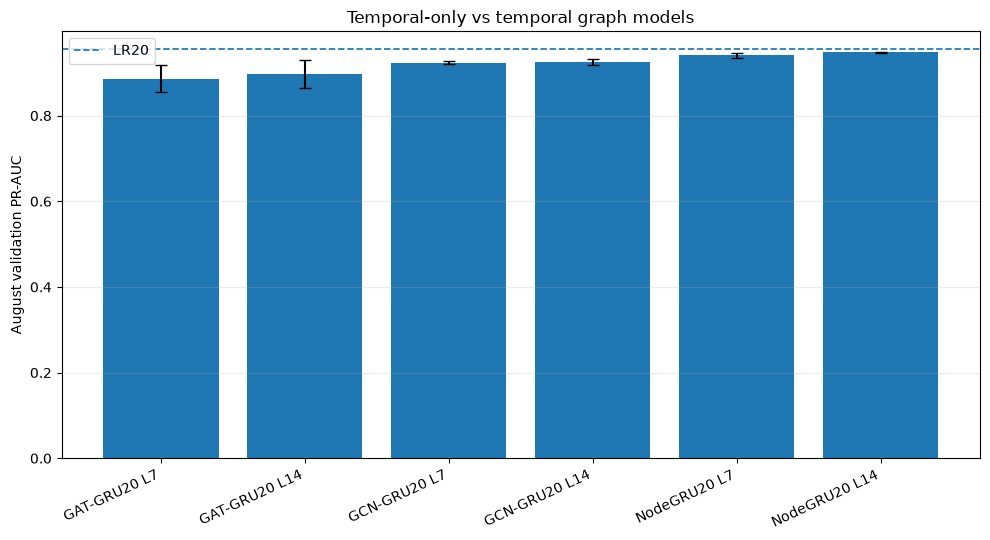

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\figures\02_temporal_graph_pr_auc_comparison.png


In [33]:
# 26. Overall validation figure

plot_df = (
    temporal_aggregate[
        [
            "Model",
            "Sequence Length",
            "PR-AUC Mean",
            "PR-AUC Std",
        ]
    ]
    .copy()
)

plot_df["Label"] = (
    plot_df["Model"]
    + " L"
    + plot_df[
        "Sequence Length"
    ].astype(str)
)

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

x = np.arange(
    len(plot_df)
)

ax.bar(
    x,
    plot_df[
        "PR-AUC Mean"
    ],
    yerr=plot_df[
        "PR-AUC Std"
    ],
    capsize=4,
)

ax.axhline(
    lr_metrics[
        "PR-AUC"
    ],
    linewidth=1.25,
    linestyle="--",
    label="LR20",
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    plot_df["Label"],
    rotation=25,
    ha="right",
)

ax.set_ylabel(
    "August validation PR-AUC"
)

ax.set_title(
    "Temporal-only vs temporal graph models"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

path = (
    FIGURES_DIR
    / "02_temporal_graph_pr_auc_comparison.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    path,
)

# PART H — 3-day Emerging-eligible evaluation

## 27. Evaluate the same overall-trained models on eligible August rows

This remains a secondary diagnostic.

The models are **not retrained** specifically on Emerging rows.

In [34]:
# 27. Eligible validation results

eligible_rows = []

# Static LR baseline on August eligible rows.
val_df_sorted = (
    val_df
    .sort_values(
        [
            "date",
            "cell_id",
        ]
    )
    .reset_index(
        drop=True
    )
)

lr_eligible_mask = (
    val_df_sorted[
        "active_days_prev3_incl_t"
    ]
    .eq(0)
    .to_numpy()
)

lr_eligible_y = (
    val_df_sorted.loc[
        lr_eligible_mask,
        target_col,
    ]
    .astype(int)
    .to_numpy()
)

lr_eligible_prob = (
    lr_val_prob[
        lr_eligible_mask
    ]
)

lr_eligible_metrics = metric_dict(
    lr_eligible_y,
    lr_eligible_prob,
)

eligible_rows.append({
    "Model": "LR20",
    "Sequence Length": 1,
    "Seed": np.nan,
    **lr_eligible_metrics,
})


for (
    model_name,
    sequence_length,
    seed,
), probability in final_val_probs.items():

    data = (
        sequence_data[
            sequence_length
        ]
    )

    masks = (
        split_masks[
            sequence_length
        ]
    )

    eligible_mask = (
        data["eligible3"][
            masks["val"]
        ]
    )

    y_val = (
        data["y"][
            masks["val"]
        ]
    )

    eligible_y = (
        y_val[
            eligible_mask
        ]
        .astype(int)
    )

    eligible_prob = (
        probability[
            eligible_mask
        ]
    )

    metrics = metric_dict(
        eligible_y,
        eligible_prob,
    )

    eligible_rows.append({
        "Model": model_name,
        "Sequence Length": sequence_length,
        "Seed": seed,
        **metrics,
    })


eligible_results = pd.DataFrame(
    eligible_rows
)

display(
    eligible_results
)

,Model,Sequence Length,Seed,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold
0,LR20,1,NaN,0.390415,0.694749,0.451613,0.459016,0.455285,0.811798,0.5
1,NodeGRU20,7,42.0,0.432451,0.741234,0.395604,0.590164,0.473684,0.775281,0.5
2,NodeGRU20,7,123.0,0.416699,0.709225,0.402597,0.508197,0.449275,0.786517,0.5
3,NodeGRU20,7,2026.0,0.409202,0.709836,0.361702,0.557377,0.438710,0.755618,0.5
4,GCN-GRU20,7,42.0,0.296381,0.652237,0.205607,0.721311,0.320000,0.474719,0.5
5,GCN-GRU20,7,123.0,0.247968,0.625340,0.216667,0.639344,0.323651,0.542135,0.5
6,GCN-GRU20,7,2026.0,0.242882,0.614115,0.209205,0.819672,0.333333,0.438202,0.5
7,GAT-GRU20,7,42.0,0.245360,0.599389,0.185811,0.901639,0.308123,0.306180,0.5
8,GAT-GRU20,7,123.0,0.228748,0.606557,0.211618,0.836066,0.337748,0.438202,0.5
9,GAT-GRU20,7,2026.0,0.260704,0.611614,0.203922,0.852459,0.329114,0.404494,0.5


## 28. Aggregate Emerging-eligible PR-AUC across seeds

In [35]:
# 28. Eligible aggregation

eligible_aggregate_rows = [
    {
        "Model": "LR20",
        "Sequence Length": 1,
        "PR-AUC Mean": lr_eligible_metrics["PR-AUC"],
        "PR-AUC Std": 0.0,
        "Precision Mean": lr_eligible_metrics["Precision"],
        "Recall Mean": lr_eligible_metrics["Recall"],
        "F1 Mean": lr_eligible_metrics["F1"],
    }
]


for (
    model_name,
    sequence_length,
), group in (
    eligible_results[
        eligible_results[
            "Model"
        ].ne(
            "LR20"
        )
    ]
    .groupby(
        [
            "Model",
            "Sequence Length",
        ]
    )
):

    eligible_aggregate_rows.append({
        "Model": model_name,
        "Sequence Length": int(
            sequence_length
        ),
        "PR-AUC Mean": group[
            "PR-AUC"
        ].mean(),
        "PR-AUC Std": group[
            "PR-AUC"
        ].std(
            ddof=1
        ),
        "Precision Mean": group[
            "Precision"
        ].mean(),
        "Recall Mean": group[
            "Recall"
        ].mean(),
        "F1 Mean": group[
            "F1"
        ].mean(),
    })


eligible_aggregate = pd.DataFrame(
    eligible_aggregate_rows
)

eligible_aggregate[
    "Δ PR-AUC vs LR20"
] = (
    eligible_aggregate[
        "PR-AUC Mean"
    ]
    - lr_eligible_metrics[
        "PR-AUC"
    ]
)

display(
    eligible_aggregate
)

,Model,Sequence Length,PR-AUC Mean,PR-AUC Std,Precision Mean,Recall Mean,F1 Mean,Δ PR-AUC vs LR20
0,LR20,1,0.390415,0.000000,0.451613,0.459016,0.455285,0.000000
1,GAT-GRU20,7,0.244937,0.015982,0.200450,0.863388,0.324995,-0.145477
2,GAT-GRU20,14,0.241573,0.028821,0.196192,0.825137,0.316845,-0.148842
3,GCN-GRU20,7,0.262410,0.029529,0.210493,0.726776,0.325662,-0.128005
4,GCN-GRU20,14,0.251569,0.013664,0.217600,0.710383,0.328666,-0.138846
5,NodeGRU20,7,0.419451,0.011866,0.386635,0.551913,0.453890,0.029036
6,NodeGRU20,14,0.421735,0.013378,0.403194,0.612022,0.463652,0.031320


## 29. Positive Persistent vs Emerging recall

Recall is meaningful within these positive-only groups.

Precision and PR-AUC are not calculated inside all-positive subgroup slices.

In [36]:
# 29. Positive subgroup recall

subgroup_rows = []

# LR probabilities to date × node matrix.
lr_prob_matrix = (
    lr_val_prob
    .reshape(
        -1,
        N_NODES,
    )
)

# event/target matrix for August static rows.
august_date_mask_static = (
    (
        all_dates
        >= pd.Timestamp(
            "2026-08-01"
        )
    )
    &
    (
        all_dates
        < pd.Timestamp(
            "2026-09-01"
        )
    )
)

lr_event_matrix = (
    event3_np[
        august_date_mask_static
    ]
)

lr_y_matrix = (
    y_np[
        august_date_mask_static
    ]
)

for event_type in [
    "Persistent",
    "Emerging",
]:

    mask = (
        (
            lr_event_matrix
            == event_type
        )
        &
        (
            lr_y_matrix
            == 1
        )
    )

    subgroup_rows.append({
        "Model": "LR20",
        "Sequence Length": 1,
        "Seed": np.nan,
        "Event Type": event_type,
        "N Positives": int(
            mask.sum()
        ),
        "Recall @0.50": float(
            (
                lr_prob_matrix[
                    mask
                ]
                >= 0.50
            ).mean()
        ),
        "Mean Probability": float(
            lr_prob_matrix[
                mask
            ].mean()
        ),
    })


for (
    model_name,
    sequence_length,
    seed,
), probability in final_val_probs.items():

    data = (
        sequence_data[
            sequence_length
        ]
    )

    masks = (
        split_masks[
            sequence_length
        ]
    )

    val_events = (
        data["event3"][
            masks["val"]
        ]
    )

    val_y = (
        data["y"][
            masks["val"]
        ]
    )

    for event_type in [
        "Persistent",
        "Emerging",
    ]:

        mask = (
            (
                val_events
                == event_type
            )
            &
            (
                val_y
                == 1
            )
        )

        subgroup_rows.append({
            "Model": model_name,
            "Sequence Length": sequence_length,
            "Seed": seed,
            "Event Type": event_type,
            "N Positives": int(
                mask.sum()
            ),
            "Recall @0.50": float(
                (
                    probability[
                        mask
                    ]
                    >= 0.50
                ).mean()
            ),
            "Mean Probability": float(
                probability[
                    mask
                ].mean()
            ),
        })


subgroup_recall = pd.DataFrame(
    subgroup_rows
)

display(
    subgroup_recall
)

,Model,Sequence Length,Seed,Event Type,N Positives,Recall @0.50,Mean Probability
0,LR20,1,NaN,Persistent,2030,0.952217,0.905958
1,LR20,1,NaN,Emerging,61,0.475410,0.507761
2,NodeGRU20,7,42.0,Persistent,2030,0.975862,0.889163
3,NodeGRU20,7,42.0,Emerging,61,0.590164,0.547431
4,NodeGRU20,7,123.0,Persistent,2030,0.963547,0.869248
5,NodeGRU20,7,123.0,Emerging,61,0.508197,0.510094
6,NodeGRU20,7,2026.0,Persistent,2030,0.962562,0.868463
7,NodeGRU20,7,2026.0,Emerging,61,0.557377,0.518439
8,GCN-GRU20,7,42.0,Persistent,2030,0.974877,0.833151
9,GCN-GRU20,7,42.0,Emerging,61,0.721311,0.638644


# PART I — Sequence-length sensitivity

## 30. Does 14 days help beyond 7 days?

This compares the same architecture across sequence lengths.

In [37]:
# 30. Sequence-length deltas

length_delta_rows = []

for model_name in MODEL_FACTORIES:

    sub = (
        temporal_aggregate[
            temporal_aggregate[
                "Model"
            ].eq(
                model_name
            )
        ]
        .set_index(
            "Sequence Length"
        )
    )

    delta = (
        sub.loc[
            14,
            "PR-AUC Mean",
        ]
        -
        sub.loc[
            7,
            "PR-AUC Mean",
        ]
    )

    length_delta_rows.append({
        "Model": model_name,
        "PR-AUC L7": sub.loc[
            7,
            "PR-AUC Mean",
        ],
        "PR-AUC L14": sub.loc[
            14,
            "PR-AUC Mean",
        ],
        "L14 − L7": delta,
    })


sequence_length_deltas = pd.DataFrame(
    length_delta_rows
)

display(
    sequence_length_deltas
)

,Model,PR-AUC L7,PR-AUC L14,L14 − L7
0,NodeGRU20,0.941148,0.948056,0.006908
1,GCN-GRU20,0.923664,0.925733,0.002069
2,GAT-GRU20,0.885756,0.897018,0.011263


# PART J — Runtime and hardware

## 31. Training-time summary

In [38]:
# 31. Runtime summary

runtime_summary = (
    temporal_results
    .groupby(
        [
            "Model",
            "Sequence Length",
        ],
        as_index=False,
    )
    .agg(
        Mean_Best_Epoch=(
            "Best Epoch",
            "mean",
        ),
        Mean_Training_Seconds=(
            "Training Seconds",
            "mean",
        ),
        Max_Training_Seconds=(
            "Training Seconds",
            "max",
        ),
    )
)

runtime_summary[
    "Device"
] = str(
    DEVICE
)

display(
    runtime_summary
)

print(
    "This is still a small 90-node graph problem. "
    "If CPU runtime is acceptable, a large GPU is not required. "
    "GPU becomes more useful later for wider hyperparameter searches "
    "or finer spatial grids."
)

,Model,Sequence Length,Mean_Best_Epoch,Mean_Training_Seconds,Max_Training_Seconds,Device
0,GAT-GRU20,7,7.333333,5.407346,9.536451,cpu
1,GAT-GRU20,14,6.666667,8.772197,13.188261,cpu
2,GCN-GRU20,7,3.333333,0.555843,0.821650,cpu
3,GCN-GRU20,14,3.333333,0.880637,1.333394,cpu
4,NodeGRU20,7,4.000000,0.446562,0.787629,cpu
5,NodeGRU20,14,7.333333,1.318478,1.799324,cpu


This is still a small 90-node graph problem. If CPU runtime is acceptable, a large GPU is not required. GPU becomes more useful later for wider hyperparameter searches or finer spatial grids.


# PART K — Save outputs for the next experiment

In [39]:
# 32. Save result tables

tables = {
    "parameter_table.csv": parameter_table,
    "split_summary.csv": split_summary,
    "tuning_summary.csv": tuning_summary,
    "tuning_aggregate.csv": tuning_aggregate,
    "tuning_history.csv": tuning_history,
    "temporal_seed_results.csv": temporal_results,
    "temporal_aggregate.csv": temporal_aggregate,
    "mechanism_deltas.csv": mechanism_deltas,
    "overall_comparison.csv": overall_comparison,
    "eligible_seed_results.csv": eligible_results,
    "eligible_aggregate.csv": eligible_aggregate,
    "subgroup_recall.csv": subgroup_recall,
    "sequence_length_deltas.csv": sequence_length_deltas,
    "runtime_summary.csv": runtime_summary,
}

for filename, dataframe in tables.items():

    path = (
        RESULTS_DIR
        / filename
    )

    dataframe.to_csv(
        path,
        index=False,
    )

    print(
        "Saved:",
        path,
    )

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\parameter_table.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\split_summary.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\tuning_summary.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\tuning_aggregate.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\tuning_history.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\temporal_seed_results.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\temporal_aggregate.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\mechanism_deltas.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\overall_comparison.csv
Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\eligible_seed_results.csv
Saved: c:\Users\Asus\Documents\skr

In [40]:
# 33. Save trained temporal model states

for (
    model_name,
    sequence_length,
    seed,
), model in final_models.items():

    safe_name = (
        model_name
        .lower()
        .replace(
            "-",
            "_",
        )
    )

    path = (
        MODELS_DIR
        / (
            f"{safe_name}"
            f"_L{sequence_length}"
            f"_seed{seed}.pt"
        )
    )

    torch.save(
        model.state_dict(),
        path,
    )

print(
    "Saved model states to:",
    MODELS_DIR,
)

Saved model states to: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\models


In [41]:
# 34. Save temporal sequence metadata

for sequence_length in SEQUENCE_LENGTHS:

    data = (
        sequence_data[
            sequence_length
        ]
    )

    np.savez_compressed(
        ARTIFACTS_DIR
        / f"temporal_sequences_L{sequence_length}.npz",
        end_dates=np.array(
            [
                str(
                    d.date()
                )
                for d in data[
                    "end_dates"
                ]
            ]
        ),
        end_positions=data[
            "end_positions"
        ],
        eligible3=data[
            "eligible3"
        ].astype(
            np.uint8
        ),
    )

print(
    "Saved temporal artifacts to:",
    ARTIFACTS_DIR,
)

Saved temporal artifacts to: c:\Users\Asus\Documents\skripsi-karhut\model_results\temporal_graph\artifacts


# PART L — Keep September unopened

In [42]:
# 35. Final-test lock

RUN_TEST = False

if RUN_TEST:

    print(
        "Do not evaluate September yet. "
        "First interpret the temporal graph validation results, "
        "then decide whether a wind-informed temporal graph ablation is justified."
    )

else:

    print(
        "RUN_TEST=False → September test probabilities were not generated."
    )

RUN_TEST=False → September test probabilities were not generated.


# 36. Automatic interpretation

The central question is not whether a graph model beats LR by any amount.

The important decomposition is:

1. does **temporal-only GRU** improve over static LR?
2. does **GCN-GRU or GAT-GRU** improve over temporal-only GRU?
3. is any graph gain stable across 7- and 14-day sequences?
4. does the same pattern hold for the 3-day Emerging-eligible diagnostic?

In [43]:
# 36. Automatic decision summary

best_overall_row = (
    temporal_aggregate
    .sort_values(
        "PR-AUC Mean",
        ascending=False,
    )
    .iloc[0]
)

best_model = (
    best_overall_row[
        "Model"
    ]
)

best_length = int(
    best_overall_row[
        "Sequence Length"
    ]
)

best_ap = float(
    best_overall_row[
        "PR-AUC Mean"
    ]
)

print(
    "=== Notebook 15 temporal graph summary ==="
)
print()

print(
    "DEVICE"
)
print(
    "Device                     :",
    DEVICE,
)
print(
    "Nodes                      :",
    N_NODES,
)
print()

print(
    "STATIC REFERENCE"
)
print(
    "LR20 PR-AUC                :",
    round(
        lr_metrics[
            "PR-AUC"
        ],
        6,
    ),
)
print()

print(
    "BEST TEMPORAL CONFIG"
)
print(
    "Model                      :",
    best_model,
)
print(
    "Sequence length            :",
    best_length,
)
print(
    "Mean validation PR-AUC     :",
    round(
        best_ap,
        6,
    ),
)
print(
    "Δ vs LR20                  :",
    f"{best_ap - lr_metrics['PR-AUC']:+.6f}",
)
print()

print(
    "GRAPH-SPECIFIC DELTAS"
)

for sequence_length in SEQUENCE_LENGTHS:

    sub = (
        temporal_aggregate[
            temporal_aggregate[
                "Sequence Length"
            ].eq(
                sequence_length
            )
        ]
        .set_index(
            "Model"
        )
    )

    node_ap = (
        sub.loc[
            "NodeGRU20",
            "PR-AUC Mean",
        ]
    )

    gcn_ap = (
        sub.loc[
            "GCN-GRU20",
            "PR-AUC Mean",
        ]
    )

    gat_ap = (
        sub.loc[
            "GAT-GRU20",
            "PR-AUC Mean",
        ]
    )

    print(
        f"L={sequence_length}: "
        f"GCN-GRU − NodeGRU = "
        f"{gcn_ap - node_ap:+.6f} | "
        f"GAT-GRU − NodeGRU = "
        f"{gat_ap - node_ap:+.6f}"
    )

print()

positive_graph_lengths = 0

for sequence_length in SEQUENCE_LENGTHS:

    sub = (
        temporal_aggregate[
            temporal_aggregate[
                "Sequence Length"
            ].eq(
                sequence_length
            )
        ]
        .set_index(
            "Model"
        )
    )

    node_ap = (
        sub.loc[
            "NodeGRU20",
            "PR-AUC Mean",
        ]
    )

    best_graph_ap = max(
        sub.loc[
            "GCN-GRU20",
            "PR-AUC Mean",
        ],
        sub.loc[
            "GAT-GRU20",
            "PR-AUC Mean",
        ],
    )

    if best_graph_ap > node_ap:
        positive_graph_lengths += 1


if positive_graph_lengths == len(
    SEQUENCE_LENGTHS
):

    print(
        "Graph structure adds positive PR-AUC beyond temporal-only GRU "
        "for both tested sequence lengths. A temporal graph architecture "
        "is supported by the current validation evidence."
    )

elif positive_graph_lengths > 0:

    print(
        "Graph structure helps for only one of the tested sequence lengths. "
        "Treat temporal graph gain as promising but sequence-length sensitive."
    )

else:

    print(
        "Neither temporal graph model beats the temporal-only GRU across "
        "the tested sequence lengths. The current 150-km static graph does "
        "not provide robust additional predictive information, even after "
        "adding temporal modeling."
    )

print()

print(
    "NEXT DECISION"
)

if positive_graph_lengths > 0:

    print(
        "Proceed with one controlled wind-informed temporal graph ablation "
        "using the better temporal graph configuration. Do not open September yet."
    )

else:

    print(
        "Before adding wind or more graph complexity, reconsider the spatial "
        "representation: finer grid, smaller geographic zoom, or alternative "
        "dynamic edges may be more justified than making GAT deeper."
    )

=== Notebook 15 temporal graph summary ===

DEVICE
Device                     : cpu
Nodes                      : 90

STATIC REFERENCE
LR20 PR-AUC                : 0.955283

BEST TEMPORAL CONFIG
Model                      : NodeGRU20
Sequence length            : 14
Mean validation PR-AUC     : 0.948056
Δ vs LR20                  : -0.007226

GRAPH-SPECIFIC DELTAS
L=7: GCN-GRU − NodeGRU = -0.017484 | GAT-GRU − NodeGRU = -0.055393
L=14: GCN-GRU − NodeGRU = -0.022323 | GAT-GRU − NodeGRU = -0.051038

Neither temporal graph model beats the temporal-only GRU across the tested sequence lengths. The current 150-km static graph does not provide robust additional predictive information, even after adding temporal modeling.

NEXT DECISION
Before adding wind or more graph complexity, reconsider the spatial representation: finer grid, smaller geographic zoom, or alternative dynamic edges may be more justified than making GAT deeper.


# What to send for review

After running Notebook 15, send:

1. **Section 20** — internal tuning aggregate
2. **Section 23** — temporal validation aggregate
3. **Section 24** — graph-specific mechanism deltas
4. **Section 25** — full comparison versus LR20
5. **Section 28** — Emerging-eligible comparison
6. **Section 30** — 7-day vs 14-day sensitivity
7. **Section 31** — runtime summary
8. **Section 36** — automatic interpretation

Also send the figure:

- `02_temporal_graph_pr_auc_comparison.png`

Do not enable the September test.